In [1]:
suppressMessages(library(Seurat))
suppressMessages(library(Signac))
suppressMessages(library(dplyr))
suppressMessages(library(ggplot2))
suppressMessages(library(future))
suppressMessages(library(parallel))
suppressMessages(library(RColorBrewer))
suppressMessages(library(viridis))
suppressMessages(library(qs))
suppressMessages(library(harmony))
suppressMessages(library(igraph))
suppressMessages(library(ggraph))
suppressMessages(library(ggrepel)) 
library(tidyr)
library(foreach)
library(doParallel)
library(tidygraph)
library(anndata)
library(randomForest)
library(pheatmap)
library(dbscan)
library(scDblFinder)
library(Matrix)

suppressMessages(library(cowplot))
# Python 环境
suppressMessages(library(reticulate))
RETICULATE_PYTHON <- "/home/chaiqw/project/mb/.venv/bin/python"
use_virtualenv("/home/chaiqw/project/mb/.venv")

Sys.setenv(
  http_proxy  = "http://10.10.50.114:45698",
  https_proxy = "http://10.10.50.114:45698"
)


# 资源设定
plan("multicore", workers = 64)
options(future.globals.maxSize = 100000 * 1024^5)



载入程序包：‘tidyr’


The following object is masked from ‘package:igraph’:

    crossing


载入需要的程序包：iterators


载入程序包：‘tidygraph’


The following object is masked from ‘package:igraph’:

    groups


The following object is masked from ‘package:stats’:

    filter



载入程序包：‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers


randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


载入程序包：‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:dplyr’:

    combine



载入程序包：‘dbscan’


The following object is masked from ‘package:stats’:

    as.dendrogram


载入需要的程序包：SingleCellExperiment

载入需要的程序包：SummarizedExperiment

载入需要的程序包：MatrixGenerics

载入需要的程序包：matrixStats


载入程序包：‘matrixStats’


The following object is masked from ‘package:dplyr’:

    count



载入程序包：‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAn

In [25]:
h5ad_path <- "/data/data0-1/motor/datasets/GSE168156_merged_CC20230722_full_mapping.h5ad"
output_rds <- "/mnt/90-connectome/Personal/CQW/midbrain/area_h5ad/RAT_VTA_dataset.rds"
output_feature_map <- "/mnt/90-connectome/Personal/CQW/midbrain/area_h5ad/RAT_feature_map.csv"

data1 <- read_h5ad(h5ad_path)

counts <- Matrix::t(data1$X)
metadata <- as.data.frame(data1$obs)
feature_metadata <- as.data.frame(data1$var)

stopifnot(nrow(counts) == nrow(feature_metadata))
stopifnot(ncol(counts) == nrow(metadata))

cell_ids <- rownames(metadata)
rat_ensembl_id <- as.character(feature_metadata$gene_id)
rat_gene_name <- as.character(feature_metadata$gene_name)


gene_symbol_upper <- toupper(trimws(rat_gene_name))
keep <- !is.na(gene_symbol_upper) & gene_symbol_upper != ""

counts <- counts[keep, , drop = FALSE]
rat_ensembl_id <- rat_ensembl_id[keep]
rat_gene_name <- rat_gene_name[keep]
gene_symbol_upper <- gene_symbol_upper[keep]


unique_symbols <- unique(gene_symbol_upper)
feature_to_symbol <- Matrix::sparseMatrix(
  i = match(gene_symbol_upper, unique_symbols),
  j = seq_along(gene_symbol_upper),
  x = 1,
  dims = c(length(unique_symbols), length(gene_symbol_upper))
)

counts <- feature_to_symbol %*% counts
rownames(counts) <- unique_symbols
colnames(counts) <- cell_ids


seurat1 <- CreateSeuratObject(
  counts = counts,
  meta.data = metadata,
  project = "GSE168156_rat_VTA"
)

feature_map <- data.frame(
  rat_ensembl_id = rat_ensembl_id,
  rat_gene_name = rat_gene_name,
  gene_symbol_upper = gene_symbol_upper
)

write.csv(feature_map, output_feature_map, row.names = FALSE)
saveRDS(seurat1, output_rds)

print(seurat1)
head(rownames(seurat1))

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”


An object of class Seurat 
28914 features across 21606 samples within 1 assay 
Active assay: RNA (28914 features, 0 variable features)
 1 layer present: counts


[1] "AABR07000046.1" "AABR07000089.1" "VOM2R6"         "VOM2R5"        
[5] "RAET1E"         "RF00421"

In [2]:
seurat1 = readRDS('/mnt/90-connectome/Personal/CQW/midbrain/area_h5ad/RAT_VTA_dataset.rds')
seurat1

An object of class Seurat 
28914 features across 21606 samples within 1 assay 
Active assay: RNA (28914 features, 0 variable features)
 1 layer present: counts

In [3]:
seurat2  = readRDS('/mnt/90-connectome/Personal/CQW/midbrain/area_h5ad/20260807_VTA_DA_seurat_cluster.rds')


Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony converged after 3 iterations

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers w

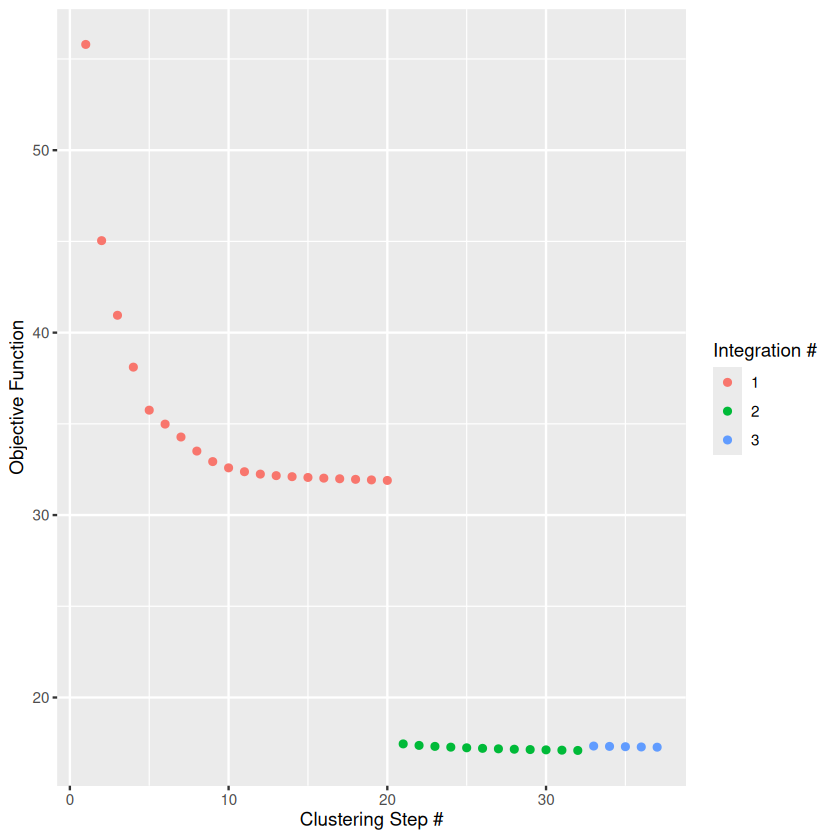

In [4]:
class_resolution = 0.3

seurat1$Animal = seurat1$gsm_id
mt_gene = c("ND6", "COX3", "COX1", "ND5", "ND4", "ND2", "ND4L", "ATP8", "CYTB", "COX2", "ND3", "ATP6", "ND1")

assay = seurat1@assays$RNA$counts
meta = seurat1@meta.data
new_assay = assay[setdiff(rownames(assay), mt_gene), ]

seurat1_sub1 = CreateSeuratObject(counts = new_assay)
seurat1_sub1 = AddMetaData(seurat1_sub1, meta)

seurat1_sub1 = NormalizeData(seurat1_sub1, normalization.method = "LogNormalize", scale.factor = 10000)
seurat1_sub1 = FindVariableFeatures(seurat1_sub1, selection.method = "vst", nfeatures = 3000)
seurat1_sub1 = ScaleData(seurat1_sub1, features = rownames(seurat1_sub1))

seurat1_sub1 = seurat1_sub1 %>%
    RunPCA(npcs = 50, verbose = FALSE) %>%
    FindNeighbors(dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(dims = 1:25, umap.method = "umap-learn")

seurat1_sub1 = RunHarmony(
    seurat1_sub1, group.by.vars = "Animal", plot_convergence = TRUE,
    reduction.save = "harmony", dims.use = 1:25,
    theta = 2
)

seurat1_sub1 = seurat1_sub1 %>%
    FindNeighbors(reduction = "harmony", dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(reduction = "harmony", dims = 1:25)

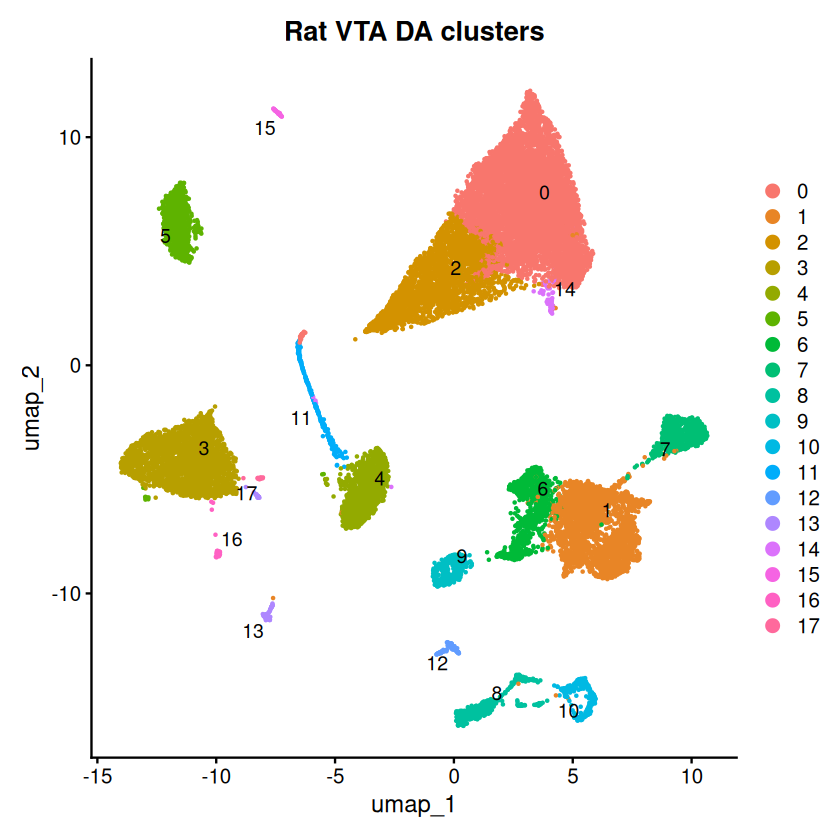

In [5]:
options(repr.plot.width=7, repr.plot.height=7)

DimPlot(seurat1_sub1, reduction = "umap", group.by = "seurat_clusters", label = TRUE, repel = TRUE) + ggtitle("Rat VTA DA clusters")

In [6]:
table(seurat1_sub1$seurat_clusters)


   0    1    2    3    4    5    6    7    8    9   10   11   12   13   14   15 
7200 2850 2584 2540 1580 1096 1059  697  479  399  350  268  135  135   81   69 
  16   17 
  64   20 

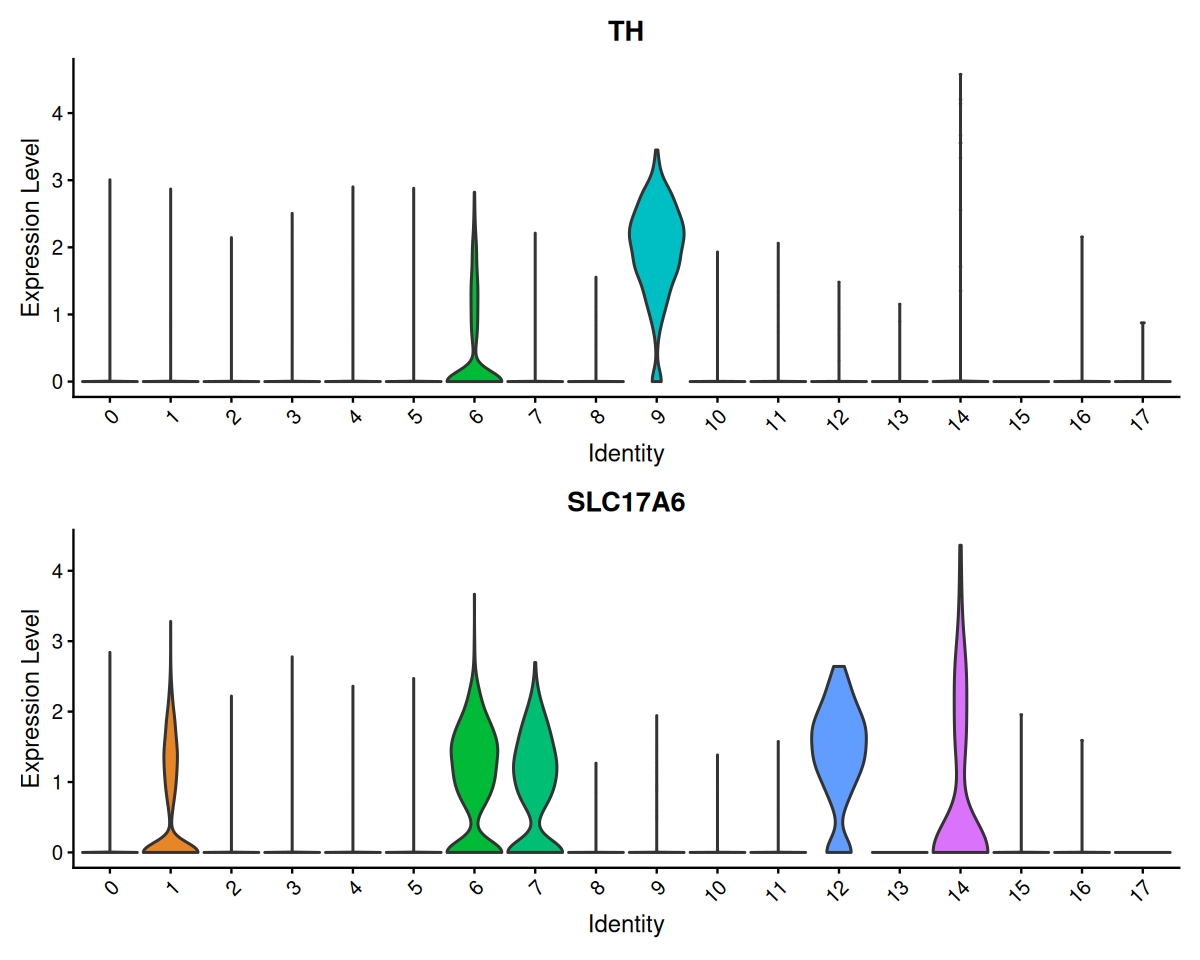

In [7]:
DefaultAssay(seurat1_sub1) <- "RNA"
options(repr.plot.width = 10, repr.plot.height = 8)
VlnPlot(
    seurat1_sub1,
    features = c("TH", "SLC17A6"),
    group.by = "seurat_clusters",
    pt.size = 0,
    ncol = 1
)

In [8]:
seurat1_sub1_filt = subset(seurat1_sub1, seurat_clusters %in% c(9))
seurat1_sub1_filt

An object of class Seurat 
28914 features across 399 samples within 1 assay 
Active assay: RNA (28914 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, harmony

Normalizing layer: counts

Finding variable features for layer counts

Centering and scaling data matrix

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via a parallel RNG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony converged after 1 iterations

Computing nearest neighbor graph

Computing SNN

Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There i

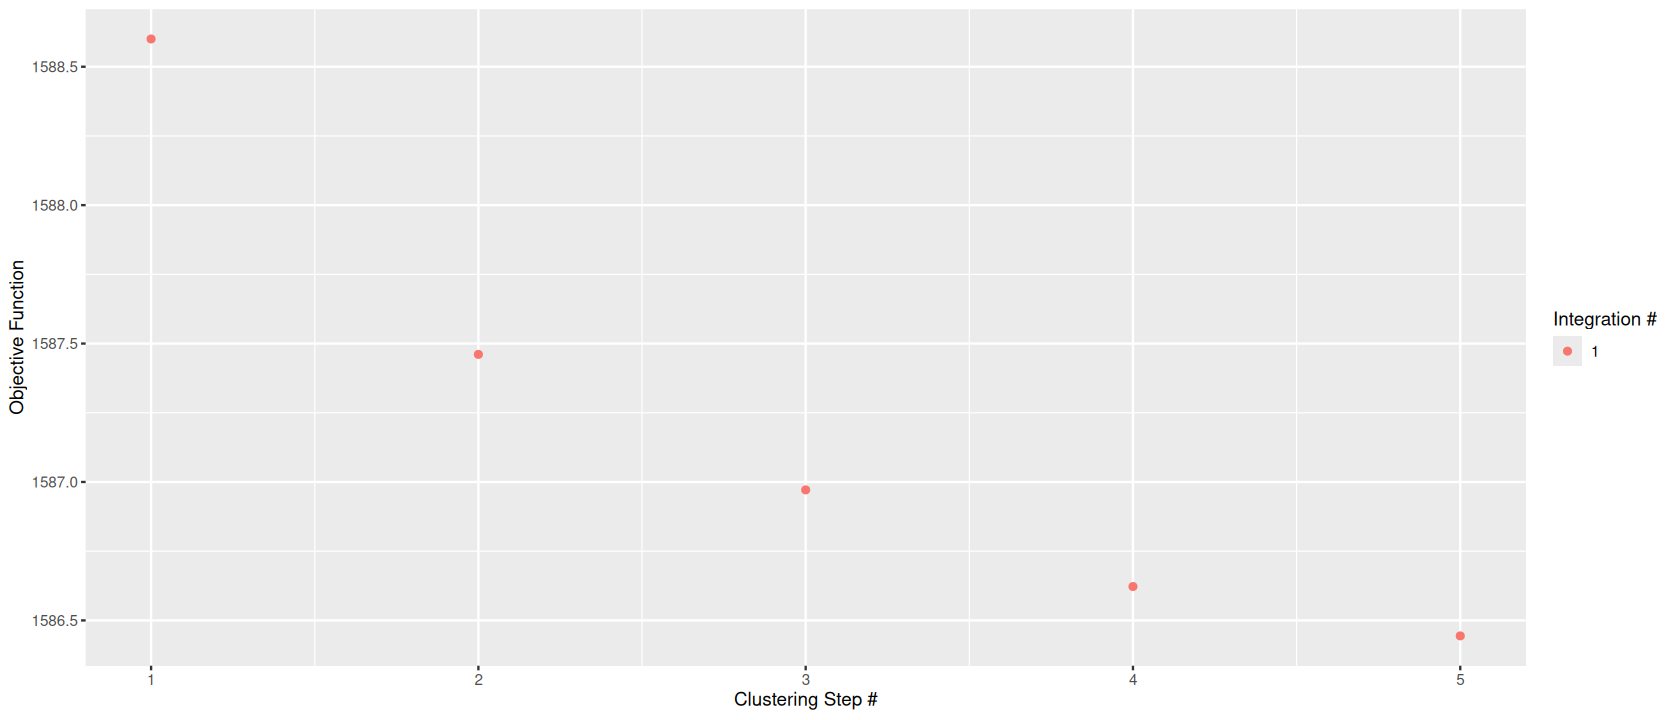

In [130]:
class_resolution = 1.2


mt_gene = c("ND6", "COX3", "COX1", "ND5", "ND4", "ND2", "ND4L", "ATP8", "CYTB", "COX2", "ND3", "ATP6", "ND1")

assay = seurat1_sub1_filt@assays$RNA$counts
meta = seurat1_sub1_filt@meta.data
new_assay = assay[setdiff(rownames(assay), mt_gene), ]

seurat1_sub1_filt1 = CreateSeuratObject(counts = new_assay)
seurat1_sub1_filt1 = AddMetaData(seurat1_sub1_filt1, meta)

seurat1_sub1_filt1 = NormalizeData(seurat1_sub1_filt1, normalization.method = "LogNormalize", scale.factor = 10000)
seurat1_sub1_filt1 = FindVariableFeatures(seurat1_sub1_filt1, selection.method = "vst", nfeatures = 3000)
seurat1_sub1_filt1 = ScaleData(seurat1_sub1_filt1, features = rownames(seurat1_sub1_filt1))

# seurat1_sub1_filt1 = SCTransform(
#     seurat1_sub1_filt1, assay="RNA",
#     ncells=ncol(seurat1_sub1_filt1[["RNA"]]),
#     vst.flavor = "v2",
#     variable.features.n=3000,
#     vars.to.regress="nCount_RNA",
#     method="glmGamPoi",
#     verbose = FALSE
# )

seurat1_sub1_filt1 = seurat1_sub1_filt1 %>%
    RunPCA(npcs = 50, verbose = FALSE) %>%
    FindNeighbors(dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(dims = 1:25, umap.method = "umap-learn")

seurat1_sub1_filt1 = RunHarmony(
    seurat1_sub1_filt1, group.by.vars = "Animal", plot_convergence = TRUE,
    reduction.save = "harmony", dims.use = 1:25,
    theta = 2
)

seurat1_sub1_filt1 = seurat1_sub1_filt1 %>%
    FindNeighbors(reduction = "harmony", dims = 1:25) %>%
    FindClusters(verbose = FALSE, resolution = class_resolution, random.seed = 1234) %>%
    RunUMAP(reduction = "harmony", dims = 1:25)

In [ ]:
saveRDS(seurat1_sub1_filt1, '/mnt/90-connectome/Personal/CQW/midbrain/datasets/rat_DA_datasets-new.rds')


: 

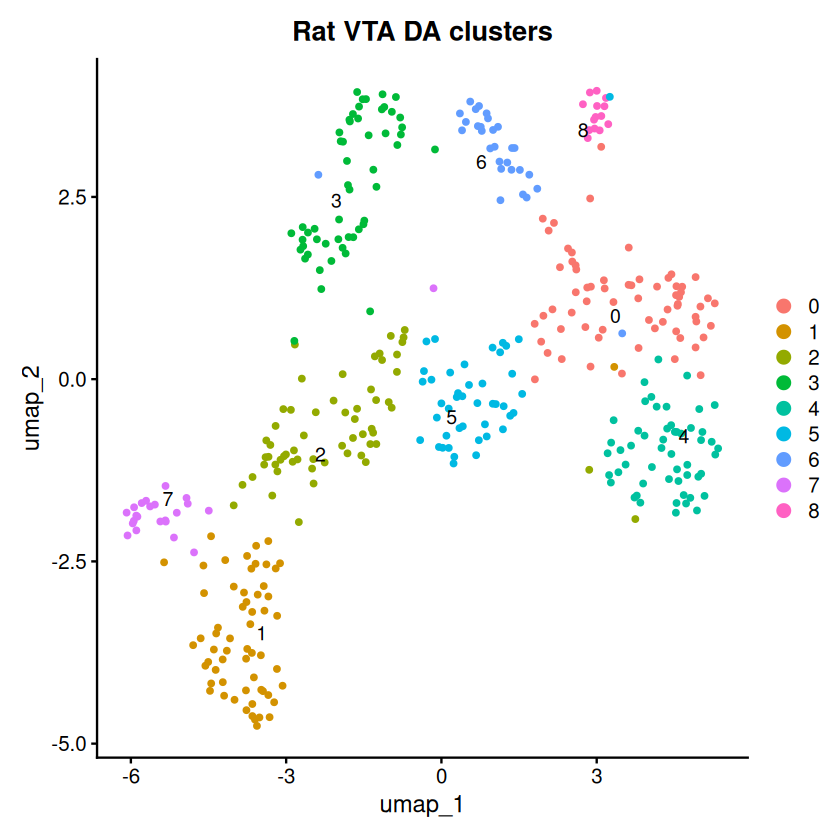

In [63]:
options(repr.plot.width=7, repr.plot.height=7)

DimPlot(seurat1_sub1_filt1, reduction = "umap", group.by = "seurat_clusters", label = TRUE, repel = TRUE) + ggtitle("Rat VTA DA clusters")

In [200]:
seurat1_sub1_filt1

An object of class Seurat 
28914 features across 399 samples within 1 assay 
Active assay: RNA (28914 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, harmony

In [162]:
seurat1_sub1_filt1$cluster = paste('DA', seurat1_sub1_filt1$seurat_clusters, sep = '_')
seurat1_sub1_filt1$Cluster = paste('rat', seurat1_sub1_filt1$cluster, sep = '_')

table(seurat1_sub1_filt1$Cluster)


rat_DA_0 rat_DA_1 rat_DA_2 rat_DA_3 rat_DA_4 rat_DA_5 rat_DA_6 rat_DA_7 
      69       61       61       60       46       40       34       16 
rat_DA_8 
      12 

In [134]:
markers = read.csv("/mnt/90-connectome/Personal/CQW/midbrain/datasets/DA_cluster_markers.csv",row.names = 1)
markers %>% head()

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
NXPH1,2.178336e-204,2.473539,0.979,0.370,4.431607e-200,DA_3,NXPH1
IL1RAPL2,7.089372e-166,2.493238,0.932,0.484,1.442262e-161,DA_3,IL1RAPL2
HTR4,1.737247e-151,2.297529,0.911,0.385,3.534256e-147,DA_3,HTR4
BRINP3,3.416391e-146,3.052145,0.801,0.250,6.950306e-142,DA_3,BRINP3
IQGAP2,2.300975e-136,2.112367,0.913,0.587,4.681104e-132,DA_3,IQGAP2
PRKCQ,9.670723e-132,1.864860,0.913,0.500,1.967412e-127,DA_3,PRKCQ


In [136]:
markers_filt = markers
MTGenes <- c("ND6","COX1","ND5","ND4","ND2","ND4L","ATP8","CYTB","COX2","ND3","ATP6","ND1","COX3")
markers_filt <- markers_filt[!markers_filt$gene %in% MTGenes, ]
markers_filt = markers_filt %>% filter(!grepl("^ENSMFAG", gene))

cluster_order = c('DA_0', 'DA_1', 'DA_2', 'DA_3', 'DA_4', 'DA_5', 'DA_6', 'DA_7', 'DA_8')

markers_filt = subset(markers_filt, p_val_adj < 0.01)
markers_filt = subset(markers_filt, avg_log2FC > 0.5)

markers_filt_top3 <- markers_filt %>%
    filter(cluster %in% cluster_order, pct.1 > 0.3) %>%
    mutate(cluster = factor(cluster, levels = cluster_order)) %>%
    group_by(cluster) %>%
    arrange(desc(avg_log2FC), .by_group = TRUE) %>%
    slice_head(n = 3) %>%
    ungroup()


In [191]:
seurat1_sub1_filt1_copy = seurat1_sub1_filt1


DA_0 DA_1 DA_2 DA_3 DA_4 DA_5 DA_6 DA_7 DA_8 
  69   61   61   60   46   40   34   16   12 

Warning message:
“Genes absent from the current assay: ZNF804B, DSCR4”
Warning message:
“All cells have the same value of FAU”


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


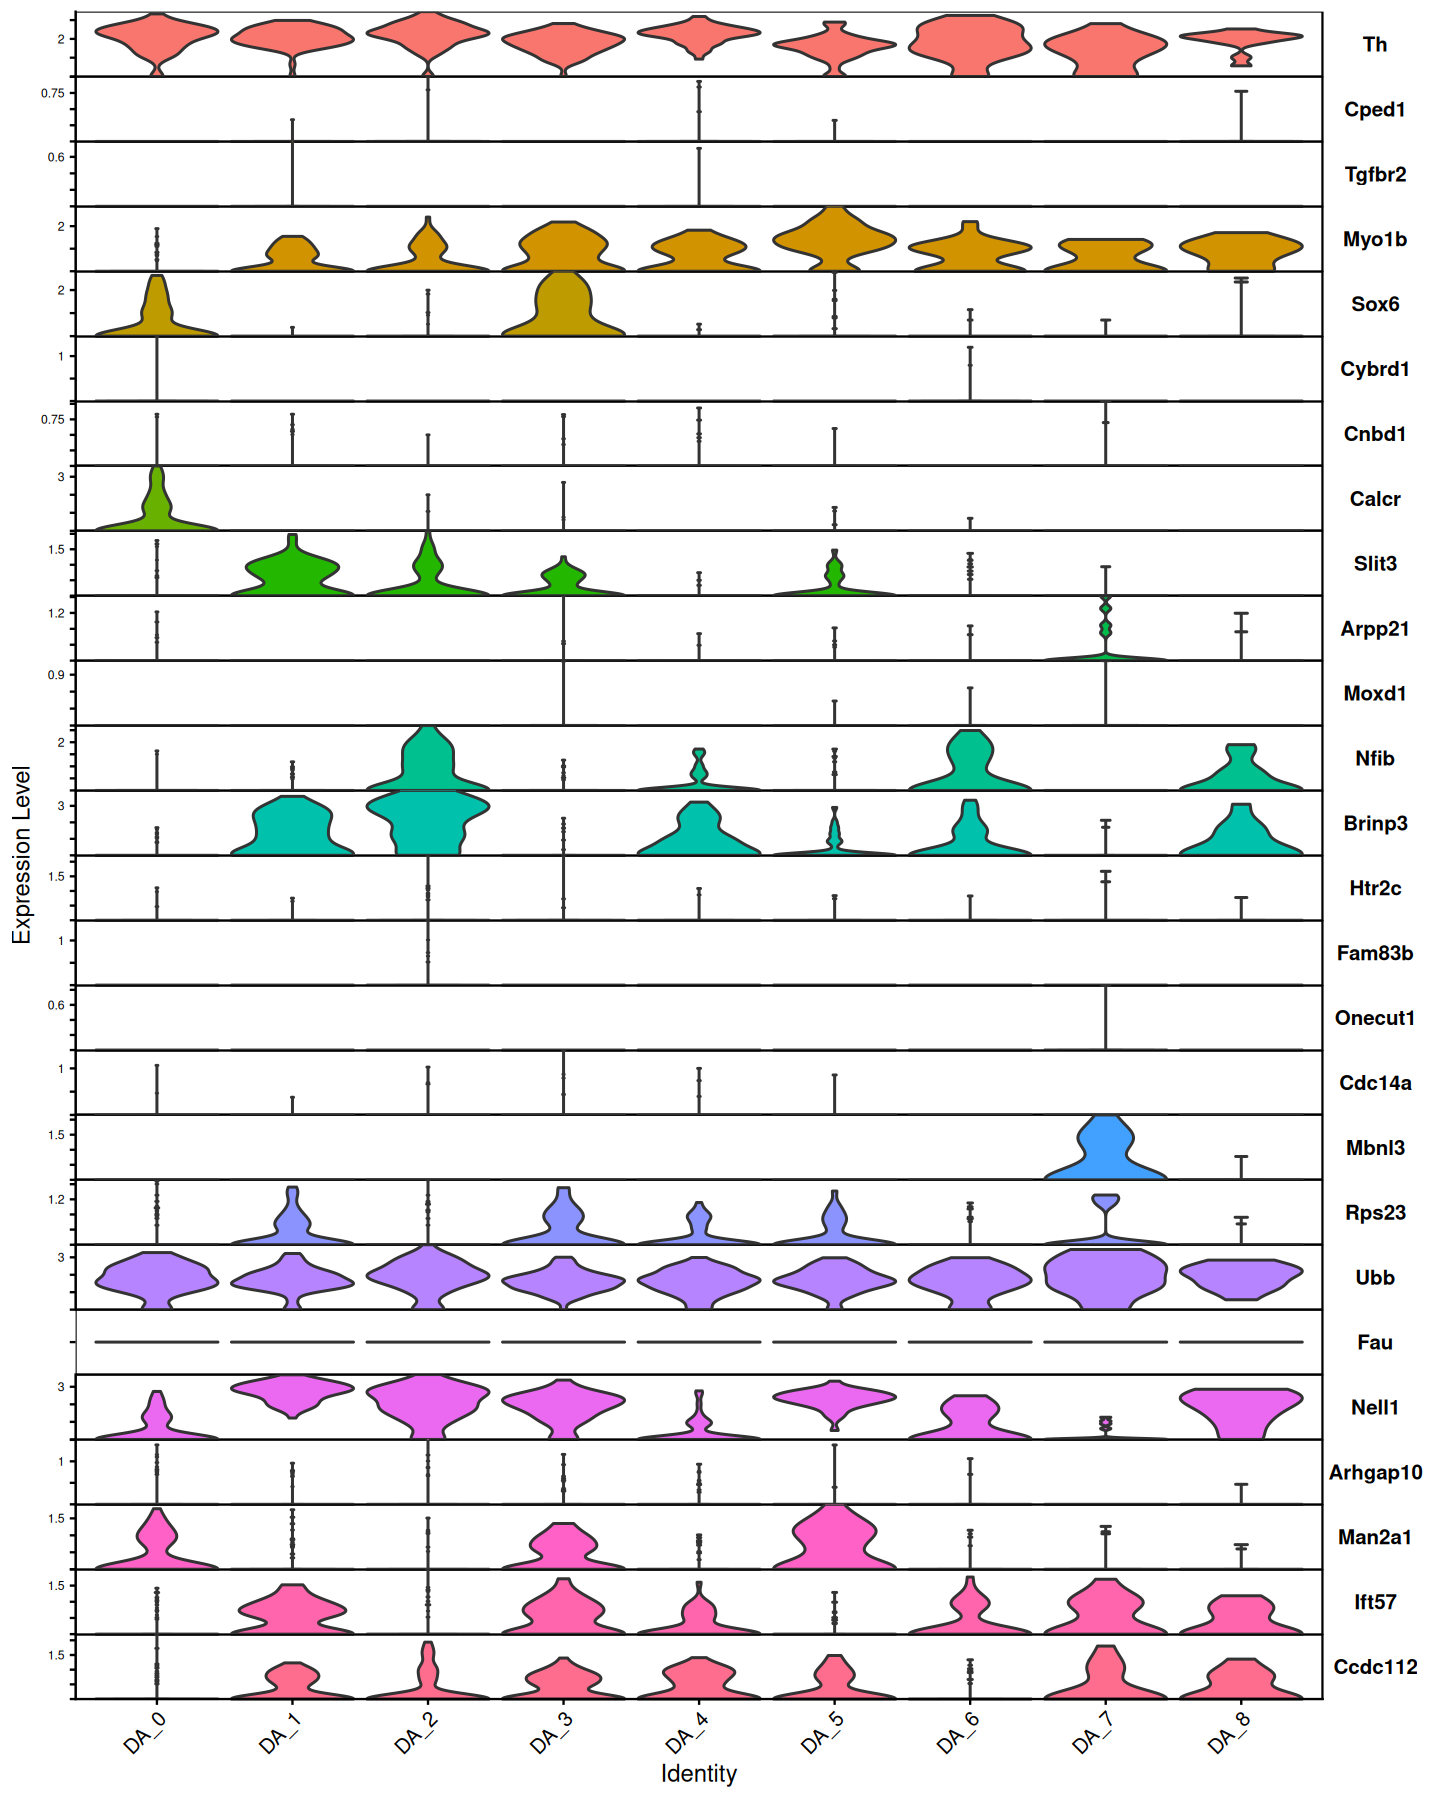

In [198]:
gene_order = c('TH', markers_filt_top3$gene)

# 分组与排序均使用元数据中的 cluster，不依赖当前 Idents
meta_plot <- seurat1_sub1_filt1_copy[[]] |>
    dplyr::transmute(
        cluster_raw = as.character(cluster)
    )

if (anyNA(meta_plot) || any(trimws(meta_plot$cluster_raw) == "")) {
    stop("Class and cluster must contain valid, non-missing labels.")
}

cluster_order <- meta_plot |>
    dplyr::distinct(cluster_raw) |>
    dplyr::arrange(cluster_raw) |>
    dplyr::pull(cluster_raw)

if (anyDuplicated(cluster_order)) {
    stop("Each cluster must belong to exactly one Class.")
}

# 仅修改绘图副本，保留 merge_2 的身份与元数据
plot_obj <- seurat1_sub1_filt1_copy

plot_obj$cluster_plot <- factor(
    meta_plot$cluster_raw,
    levels = cluster_order
)

Idents(plot_obj) <- "cluster_plot"

table(plot_obj$cluster_plot, useNA = "ifany")

cell_count <- plot_obj[[]] |>
    dplyr::count(cluster_plot, name = "n")


missing_features <- setdiff(gene_order, rownames(plot_obj[[DefaultAssay(plot_obj)]]))
if (length(missing_features) > 0L) {
    warning("Genes absent from the current assay: ", paste(missing_features, collapse = ", "))
}
gene_order <- setdiff(gene_order, missing_features)
if (length(gene_order) == 0L) {
    stop("No requested genes were found in the current assay.")
}

# Constant-expression facets can have fewer than two axis breaks.
stacked_violin_labels <- function(x) {
    n <- length(x)
    labels <- rep("", n)
    if (n >= 2L) {
        labels[n - 1L] <- as.character(x[n - 1L])
    }
    labels
}

options(repr.plot.width = 12, repr.plot.height = 15)
p_vln <- VlnPlot(
    plot_obj,
    features = gene_order,
    group.by = "cluster_plot",
    pt.size = 0,
    stack = TRUE,
    flip = TRUE,
    sort = FALSE
) + ggplot2::scale_y_continuous(expand = c(0, 0), labels = stacked_violin_labels) +
    ggplot2::theme(legend.position = "none")

p_vln$facet$params$labeller <- ggplot2::labeller(
    feature = function(x) paste0(toupper(substr(x, 1, 1)), tolower(substring(x, 2)))
)

print(p_vln)

In [199]:
pdf("/mnt/90-connectome/Personal/CQW/midbrain/figure/vln_rat_gene_expression-new.pdf", width = 12, height = 15)

options(repr.plot.width = 12, repr.plot.height = 15)
p_vln <- VlnPlot(
    plot_obj,
    features = gene_order,
    group.by = "cluster_plot",
    pt.size = 0,
    stack = TRUE,
    flip = TRUE,
    sort = FALSE
) + ggplot2::scale_y_continuous(expand = c(0, 0), labels = stacked_violin_labels) +
    ggplot2::theme(legend.position = "none")

p_vln$facet$params$labeller <- ggplot2::labeller(
    feature = function(x) paste0(toupper(substr(x, 1, 1)), tolower(substring(x, 2)))
)

print(p_vln)
    
dev.off()

Warning message:
“All cells have the same value of FAU”
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


agg_record_97289282 
                  2